In [3]:
# from google.colab import drive
# drive.mount('/content/drive')

In [4]:
# !unzip "/content/drive/MyDrive/lung_colon_image_set.zip"

In [19]:
import os, sys, gc, json, time, zipfile, warnings
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             matthews_corrcoef, cohen_kappa_score, balanced_accuracy_score,
                             roc_auc_score, average_precision_score, log_loss,
                             confusion_matrix, roc_curve, precision_recall_curve)

warnings.filterwarnings('ignore')
SMOKE = os.environ.get('LCC_SMOKE') == '1'          # used only for the offline code test
IN_COLAB = 'google.colab' in sys.modules

CFG = dict(
    ZIP_PATH   = '/content/drive/MyDrive/lung/dataset/lung_colon_image_set.zip',
    DATA_DIR   = '/content/lung_colon_image_set',            # extracted on the local disk (fast)
    OUT_DIR    = '/content/drive/MyDrive/lung/lccnet_v2',    # everything worth keeping goes to Drive
    IMG        = 128,
    BATCH      = 32,
    EVAL_BATCH = 64,
    EPOCHS     = 50,
    LR         = 1e-4,
    PATIENCE   = 10,
    MONITOR    = 'val_loss',        # early stopping and checkpoint metric
    SEEDS      = [42, 43, 44],      # mean and SD across seeds. The control, Grad-CAM and efficiency use the first seed.
    SPLIT      = (0.70, 0.15, 0.15),
    GROUPS_PER_CLASS = 200,         # LC25000 has ~250 originals per class. Fewer clusters is the safer side.
    LEAK_PURGE_SIM = None,          # e.g. 0.97 drops val/test images this similar to a training image
    MIXED_PRECISION = False,        # float32 matches the earlier runs. Set True for speed, and then report it in the paper.
    N_BOOT     = 500,
    EMBED_WEIGHTS = 'imagenet',
    RUN_RANDOM_SPLIT_CONTROL = True,    # trains once on a naive random split to measure inflation
    RUN_ABLATION = True,               # 8 full training runs. Resumable.
)
if SMOKE:
    CFG.update(ZIP_PATH=None, DATA_DIR='/tmp/fake/lung_colon_image_set', OUT_DIR='/tmp/lcc_out',
               EPOCHS=2, GROUPS_PER_CLASS=8, N_BOOT=20, EMBED_WEIGHTS=None, MIXED_PRECISION=False,
               RUN_RANDOM_SPLIT_CONTROL=True, RUN_ABLATION=False, BATCH=8, EVAL_BATCH=8, SEEDS=[42, 43])

CLASSES = ['colon_aca', 'colon_n', 'lung_aca', 'lung_n', 'lung_scc']
IMG, OUT = CFG['IMG'], CFG['OUT_DIR']
RUNS, PLOTS = f'{OUT}/runs', f'{OUT}/plots'

if IN_COLAB and not os.path.exists('/content/drive/MyDrive'):
    from google.colab import drive
    drive.mount('/content/drive')
for d in (OUT, RUNS, PLOTS):
    os.makedirs(d, exist_ok=True)

if not os.path.isdir(CFG['DATA_DIR']):
    print('Extracting dataset ...')
    with zipfile.ZipFile(CFG['ZIP_PATH']) as z:
        z.extractall(os.path.dirname(CFG['DATA_DIR']))

print('TensorFlow', tf.__version__, '| GPUs:', tf.config.list_physical_devices('GPU'))

TensorFlow 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Index and cache the images
The old notebook used the two folders ("Train and Validation Set" and "Test Set") as the split. Here all 25,000 images are pooled first, because the new split is built from groups. Images are decoded once and stored as uint8.

In [6]:
rows = []
for root, _, files in os.walk(CFG['DATA_DIR']):
    cls = os.path.basename(root)
    if cls in CLASSES:
        rows += [(os.path.join(root, f), cls) for f in files if f.lower().endswith(('.jpeg', '.jpg', '.png'))]
df = pd.DataFrame(rows, columns=['path', 'class']).sort_values('path').reset_index(drop=True)
df['label'] = df['class'].map({c: i for i, c in enumerate(CLASSES)})
print(df['class'].value_counts().sort_index())
if not SMOKE:
    assert len(df) == 25000, f'expected 25,000 images, found {len(df)}'

def _load(p):
    im = Image.open(p)
    im.draft('RGB', (IMG, IMG))                 # fast JPEG decode at reduced size
    return np.asarray(im.convert('RGB').resize((IMG, IMG), Image.BILINEAR))

IDX_CSV, X_NPY = f'{OUT}/index.csv', f'{OUT}/images_{IMG}.npy'
if os.path.exists(IDX_CSV) and os.path.exists(X_NPY) and pd.read_csv(IDX_CSV)['path'].tolist() == df['path'].tolist():
    X = np.load(X_NPY)
    print('Loaded cached images', X.shape)
else:
    X = np.empty((len(df), IMG, IMG, 3), np.uint8)
    with ThreadPoolExecutor(max_workers=(os.cpu_count() or 2)) as ex:
        for i, a in enumerate(ex.map(_load, df['path'])):
            X[i] = a
    np.save(X_NPY, X); df[['path', 'class', 'label']].to_csv(IDX_CSV, index=False)
    print('Cached images', X.shape)
y_all = df['label'].values.astype(np.int32)

class
colon_aca    5000
colon_n      5000
lung_aca     5000
lung_n       5000
lung_scc     5000
Name: count, dtype: int64
Loaded cached images (25000, 128, 128, 3)


## 2. Near-duplicate groups
Each image is embedded with a frozen ImageNet MobileNetV2. The embedding is averaged over the 8 flip and rotation views, so flipped or rotated copies land close together. Within each class, agglomerative clustering (cosine, average linkage) forms the groups. A cluster is never split across partitions.

This is a proxy, because the original source IDs of LC25000 are not published. Clusters that are too large are safe but make the split less even. Clusters that are too small can still leak. The nearest-neighbour check below shows how much leakage remains.

In [7]:
def dihedral_views(x):
    for k in range(4):
        r = tf.image.rot90(x, k)
        yield r
        yield tf.image.flip_left_right(r)

def compute_embeddings(X, bs=256):
    base = keras.applications.MobileNetV2(input_shape=(IMG, IMG, 3), include_top=False,
                                          weights=CFG['EMBED_WEIGHTS'], pooling='avg')
    @tf.function
    def f(x):
        return base(keras.applications.mobilenet_v2.preprocess_input(x), training=False)
    E = np.empty((len(X), base.output_shape[-1]), np.float32)
    for i in range(0, len(X), bs):
        xb = tf.constant(X[i:i + bs], tf.float32)
        acc = tf.add_n([f(v) for v in dihedral_views(xb)]) / 8.0
        E[i:i + bs] = acc.numpy()
    return E / (np.linalg.norm(E, axis=1, keepdims=True) + 1e-8)

EMB_NPY = f'{OUT}/embeddings_mnv2_{IMG}.npy'
if os.path.exists(EMB_NPY) and np.load(EMB_NPY, mmap_mode='r').shape[0] == len(X):
    E = np.load(EMB_NPY)
else:
    t0 = time.time(); E = compute_embeddings(X); np.save(EMB_NPY, E)
    print(f'Embeddings done in {time.time() - t0:.0f}s')

def build_groups(E, labels, k):
    group = np.zeros(len(labels), np.int64)
    for c in np.unique(labels):
        idx = np.where(labels == c)[0]
        lab = AgglomerativeClustering(n_clusters=min(k, len(idx)), metric='cosine', linkage='average').fit(E[idx]).labels_
        group[idx] = c * 10000 + lab
    return group

df['group'] = build_groups(E, y_all, CFG['GROUPS_PER_CLASS'])
sz = df.groupby('group').size()
print(f'{len(sz)} groups | images per group: min {sz.min()}, median {int(sz.median())}, max {sz.max()}')
df[['path', 'class', 'label', 'group']].to_csv(f'{OUT}/groups.csv', index=False)

1000 groups | images per group: min 1, median 18, max 387


## 3. Splits (70/15/15), with a leakage check
Whole groups are assigned to a partition, class by class, so every class keeps the same ratios. The saved CSV lets the baselines (ResNet, VGG, DNN, HDE-HistNet) use exactly the same partitions.

In [8]:
def make_split(df, seed, mode='group', ratios=CFG['SPLIT']):
    rng = np.random.RandomState(seed)
    gid = df['group'].values if mode == 'group' else np.arange(len(df))   # 'random' = every image is its own group
    split = np.empty(len(df), dtype=object)
    for c in sorted(df['label'].unique()):
        idx = np.where(df['label'].values == c)[0]
        uniq, inv = np.unique(gid[idx], return_inverse=True)
        sizes = np.bincount(inv)
        target, got = np.array(ratios) * len(idx), np.zeros(3)
        assign = np.zeros(len(uniq), int)
        for u in rng.permutation(len(uniq)):
            k = int(np.argmax(target - got)); assign[u] = k; got[k] += sizes[u]
        split[idx] = np.array(['train', 'val', 'test'])[assign[inv]]
    if mode == 'group':
        assert (pd.Series(split).groupby(gid).nunique() == 1).all(), 'a group crosses partitions'
    missing = [(c, p) for c in sorted(df['label'].unique()) for p in ('train', 'val', 'test')
               if not ((split == p) & (df['label'].values == c)).any()]
    assert not missing, f'class/partition pairs with no images: {missing}. Increase GROUPS_PER_CLASS.'
    return split

def nn_similarity(E, split, chunk=1024):
    tr, out = E[split == 'train'], {}
    for s in ('val', 'test'):
        q = E[split == s]; m = np.empty(len(q), np.float32)
        for i in range(0, len(q), chunk):
            m[i:i + chunk] = (q[i:i + chunk] @ tr.T).max(1)
        out[s] = m
    return out

def get_split(seed, mode='group'):
    split = make_split(df, seed, mode)
    if CFG['LEAK_PURGE_SIM']:
        sims = nn_similarity(E, split)
        for s in ('val', 'test'):
            ii = np.where(split == s)[0]; split[ii[sims[s] >= CFG['LEAK_PURGE_SIM']]] = 'dropped'
    out = df[['path', 'class', 'label', 'group']].copy(); out['split'] = split
    out.to_csv(f'{RUNS}/split_{mode}_seed{seed}.csv', index=False)
    return split

# leakage diagnostic: cosine similarity of each test image to its closest training image
diag = []
for mode in ('random', 'group'):
    sp = make_split(df, CFG['SEEDS'][0], mode)
    s = nn_similarity(E, sp)['test']
    diag.append(dict(split=mode, mean=s.mean(), p50=np.percentile(s, 50), p90=np.percentile(s, 90), p99=np.percentile(s, 99)))
print('Nearest training neighbour of each test image (cosine similarity, lower is safer):')
print(pd.DataFrame(diag).round(4).to_string(index=False))
sp = get_split(CFG['SEEDS'][0])
print(pd.crosstab(df['class'], sp))

Nearest training neighbour of each test image (cosine similarity, lower is safer):
 split   mean    p50    p90    p99
random 0.9857 0.9908 1.0000 1.0000
 group 0.9005 0.9024 0.9434 0.9734
col_0      test  train  val
class                      
colon_aca   743   3519  738
colon_n     757   3496  747
lung_aca    782   3496  722
lung_n      749   3499  752
lung_scc    756   3504  740


## 4. Model
Same architecture as the paper. Augmentation is part of the model and active only during training, so validation, test, latency and Grad-CAM all see clean images. The augmentation follows Algorithm 1 of the paper.

In [9]:
def apply_precision():
    # keras.backend.clear_session() resets the policy to float32, so this runs before every model build
    on = CFG['MIXED_PRECISION'] and tf.config.list_physical_devices('GPU')
    keras.mixed_precision.set_global_policy('mixed_float16' if on else 'float32')

apply_precision()
print('Compute policy:', keras.mixed_precision.global_policy().name)

@keras.utils.register_keras_serializable(package='lcc')
class PositionalEmbedding(layers.Layer):
    def __init__(self, seq_len, dim, **kw):
        super().__init__(**kw); self.seq_len, self.dim = seq_len, dim
    def build(self, input_shape):
        self.pos = self.add_weight(name='pos', shape=(self.seq_len, self.dim),
                                   initializer=keras.initializers.RandomUniform(-0.05, 0.05))
    def call(self, x):
        return x + tf.cast(self.pos, x.dtype)
    def get_config(self):
        return {**super().get_config(), 'seq_len': self.seq_len, 'dim': self.dim}

def transformer_block(x, heads, key_dim, ff_dim, drop, name):
    a = layers.MultiHeadAttention(num_heads=heads, key_dim=key_dim, name=f'{name}_mhsa')(x, x)
    x = layers.LayerNormalization(name=f'{name}_ln1')(layers.Add()([x, a]))
    f = layers.Dense(ff_dim, activation='relu', name=f'{name}_ff1')(x)
    f = layers.Dense(x.shape[-1], name=f'{name}_ff2')(f)
    x = layers.LayerNormalization(name=f'{name}_ln2')(layers.Add()([x, f]))
    return layers.Dropout(drop, name=f'{name}_drop')(x)

def build_lccnet(num_classes=5, use_pos=True, n_blocks=2, n_stages=3, head_dim=512, augment=True,
                 extra_convs=0, heads=4, key_dim=32, ff_dim=256, tdrop=0.1):
    inp = keras.Input((IMG, IMG, 3), name='image')                 # float32, range 0..255
    x = inp
    if augment:
        aug = [layers.RandomFlip('horizontal', name='aug_flip'),
               layers.RandomRotation(15 / 360, fill_mode='reflect', name='aug_rot'),
               layers.RandomTranslation(0.1, 0.1, fill_mode='reflect', name='aug_shift'),
               layers.RandomZoom((-0.2, 0.2), fill_mode='reflect', name='aug_zoom'),
               layers.RandomBrightness(0.1, value_range=(0, 255), name='aug_bright')]
        if hasattr(layers, 'RandomShear'):
            aug.insert(3, layers.RandomShear(0.1, 0.1, fill_mode='reflect', name='aug_shear'))
        else:
            print('Note: this Keras version has no RandomShear, so shear augmentation is skipped.')
        for a in aug:
            x = a(x)
    x = layers.Rescaling(1 / 255., name='rescale')(x)
    for i, f in enumerate({3: [32, 64, 128], 2: [32, 128]}[n_stages]):
        x = layers.Conv2D(f, 3, padding='same', activation='relu', name=f'conv{i + 1}')(x)
        x = layers.MaxPooling2D(2, name=f'pool{i + 1}')(x)
    if n_blocks > 0:
        side, C = x.shape[1], x.shape[-1]
        x = layers.Reshape((side * side, C), name='tokens')(x)
        if use_pos:
            x = PositionalEmbedding(side * side, C, name='pos_emb')(x)
        for b in range(n_blocks):
            x = transformer_block(x, heads, key_dim, ff_dim, tdrop, f'tb{b + 1}')
        x = layers.GlobalAveragePooling1D(name='gap')(x)
    else:
        for j in range(extra_convs):                                # used by the parameter-matched CNN control
            x = layers.Conv2D(x.shape[-1], 3, padding='same', activation='relu', name=f'xconv{j + 1}')(x)
        x = layers.GlobalAveragePooling2D(name='gap')(x)
    x = layers.Dropout(0.3, name='drop1')(x)
    x = layers.Dense(head_dim, activation='relu', name='fc')(x)
    x = layers.Dropout(0.4, name='drop2')(x)
    out = layers.Dense(num_classes, activation='softmax', dtype='float32', name='probs')(x)
    return keras.Model(inp, out, name='LCC_Net')

m = build_lccnet()
n_par = m.count_params()
print(f'Parameters: {n_par:,}', '(matches the paper)' if n_par == 459589 else '<-- paper reports 459,589, check the config')
m.summary(line_length=100)
del m

Compute policy: float32
Parameters: 459,589 (matches the paper)


Model: "LCC_Net"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                ┃ Output Shape            ┃        Param # ┃ Connected to            ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)          │ (None, 128, 128, 3)     │              0 │ -                       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ aug_flip (RandomFlip)       │ (None, 128, 128, 3)     │              0 │ image[0][0]             │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ aug_rot (RandomRotation)    │ (None, 128, 128, 3)     │              0 │ aug_flip[0][0]          │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ aug_shift                   │ (None, 128, 128, 3)     │              0 │ aug_rot[0][0]           │
│ (RandomTranslation)         │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ aug_shear (RandomShear)     │ (None, 128, 128, 3)     │              0 │ aug_shift[0][0]         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ aug_zoom (RandomZoom)       │ (None, 128, 128, 3)     │              0 │ aug_shear[0][0]         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ aug_bright                  │ (None, 128, 128, 3)     │              0 │ aug_zoom[0][0]          │
│ (RandomBrightness)          │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ rescale (Rescaling)         │ (None, 128, 128, 3)     │              0 │ aug_bright[0][0]        │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ conv1 (Conv2D)              │ (None, 128, 128, 32)    │            896 │ rescale[0][0]           │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ pool1 (MaxPooling2D)        │ (None, 64, 64, 32)      │              0 │ conv1[0][0]             │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ conv2 (Conv2D)              │ (None, 64, 64, 64)      │         18,496 │ pool1[0][0]             │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ pool2 (MaxPooling2D)        │ (None, 32, 32, 64)      │              0 │ conv2[0][0]             │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ conv3 (Conv2D)              │ (None, 32, 32, 128)     │         73,856 │ pool2[0][0]             │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ pool3 (MaxPooling2D)        │ (None, 16, 16, 128)     │              0 │ conv3[0][0]             │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ tokens (Reshape)            │ (None, 256, 128)        │              0 │ pool3[0][0]             │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ pos_emb                     │ (None, 256, 128)        │         32,768 │ tokens[0][0]            │
│ (PositionalEmbedding)       │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ tb1_mhsa                    │ (None, 256, 128)        │         66,048 │ pos_emb[0][0],          │
│ (MultiHeadAttention)        │                         │    

 Total params: 459,589 (1.75 MB)

 Trainable params: 459,589 (1.75 MB)

 Non-trainable params: 0 (0.00 B)

## 5. Data pipeline, metrics and plots

In [10]:
def make_ds(idx, training, seed=0):
    ds = tf.data.Dataset.from_tensor_slices((X[idx], y_all[idx]))
    if training:
        ds = ds.shuffle(min(len(idx), 4096), seed=seed, reshuffle_each_iteration=True)
    ds = ds.batch(CFG['BATCH'] if training else CFG['EVAL_BATCH'])
    ds = ds.map(lambda a, b: (tf.cast(a, tf.float32), b), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

def ece_score(y, prob, bins=15):
    conf, ok = prob.max(1), (prob.argmax(1) == y)
    edges, e = np.linspace(0, 1, bins + 1), 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        mk = (conf > lo) & (conf <= hi)
        if mk.any():
            e += mk.mean() * abs(ok[mk].mean() - conf[mk].mean())
    return float(e)

def compute_metrics(y, prob):
    n = len(CLASSES); prob = prob / prob.sum(1, keepdims=True); pred = prob.argmax(1)
    Y = np.eye(n)[y]; cm = confusion_matrix(y, pred, labels=range(n))
    tp = np.diag(cm); fn = cm.sum(1) - tp; fp = cm.sum(0) - tp; tn = cm.sum() - tp - fn - fp
    m = dict(accuracy=accuracy_score(y, pred), macro_precision=precision_score(y, pred, average='macro'),
             macro_recall=recall_score(y, pred, average='macro'), macro_f1=f1_score(y, pred, average='macro'),
             mcc=matthews_corrcoef(y, pred), kappa=cohen_kappa_score(y, pred),
             balanced_acc=balanced_accuracy_score(y, pred),
             auroc_macro=roc_auc_score(Y, prob, average='macro'), auprc_macro=average_precision_score(Y, prob, average='macro'),
             ece=ece_score(y, prob), nll=log_loss(y, prob, labels=range(n)))
    m['per_class'] = {c: dict(sensitivity=float(tp[i] / max(tp[i] + fn[i], 1)), specificity=float(tn[i] / max(tn[i] + fp[i], 1)),
                              auroc=float(roc_auc_score(Y[:, i], prob[:, i])), auprc=float(average_precision_score(Y[:, i], prob[:, i])))
                      for i, c in enumerate(CLASSES)}
    m['confusion_matrix'] = cm.tolist()
    return {k: (float(v) if not isinstance(v, (dict, list)) else v) for k, v in m.items()}

def group_bootstrap_ci(y, prob, groups, n_boot, seed=0):
    """Resamples whole groups, because images inside a group are not independent."""
    rng = np.random.RandomState(seed); ug = np.unique(groups)
    members = {g: np.where(groups == g)[0] for g in ug}; st = defaultdict(list)
    for _ in range(n_boot):
        ii = np.concatenate([members[g] for g in rng.choice(ug, len(ug), replace=True)])
        yb, pr = y[ii], prob[ii].argmax(1)
        st['accuracy'].append((pr == yb).mean()); st['macro_f1'].append(f1_score(yb, pr, average='macro'))
        st['mcc'].append(matthews_corrcoef(yb, pr)); st['balanced_acc'].append(balanced_accuracy_score(yb, pr))
    return {k: [float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))] for k, v in st.items()}

def plot_curves(hist, path):
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    for a, k, t in zip(ax, ['accuracy', 'loss'], ['Accuracy', 'Loss']):
        a.plot(hist[k], label='train'); a.plot(hist['val_' + k], label='validation'); a.set_title(t); a.set_xlabel('epoch'); a.legend()
    plt.tight_layout(); plt.savefig(path, dpi=300); plt.show()

def plot_eval(y, prob, tag):
    n = len(CLASSES); cm = confusion_matrix(y, prob.argmax(1), labels=range(n)); Y = np.eye(n)[y]
    fig, ax = plt.subplots(1, 4, figsize=(22, 4.8))
    ax[0].imshow(cm, cmap='Blues'); ax[0].set_title('Confusion matrix (test)')
    ax[0].set_xticks(range(n)); ax[0].set_xticklabels(CLASSES, rotation=45, ha='right'); ax[0].set_yticks(range(n)); ax[0].set_yticklabels(CLASSES)
    for i in range(n):
        for j in range(n):
            ax[0].text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black')
    for i, c in enumerate(CLASSES):
        f, t, _ = roc_curve(Y[:, i], prob[:, i]); ax[1].plot(f, t, label=c)
        p, r, _ = precision_recall_curve(Y[:, i], prob[:, i]); ax[2].plot(r, p, label=c)
    ax[1].plot([0, 1], [0, 1], 'k--', lw=1); ax[1].set_title('ROC (one vs rest)'); ax[1].set_xlabel('FPR'); ax[1].set_ylabel('TPR'); ax[1].legend(fontsize=8)
    ax[2].set_title('Precision-recall'); ax[2].set_xlabel('Recall'); ax[2].set_ylabel('Precision'); ax[2].legend(fontsize=8)
    conf, ok = prob.max(1), (prob.argmax(1) == y); edges = np.linspace(0, 1, 11); xs, ys = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        mk = (conf > lo) & (conf <= hi)
        if mk.sum() >= 5: xs.append(conf[mk].mean()); ys.append(ok[mk].mean())
    ax[3].plot([0, 1], [0, 1], 'k--', lw=1); ax[3].plot(xs, ys, 'o-'); ax[3].set_title('Reliability (top-1 confidence)'); ax[3].set_xlabel('confidence'); ax[3].set_ylabel('accuracy')
    plt.tight_layout(); plt.savefig(f'{PLOTS}/{tag}_eval.png', dpi=300); plt.show()

## 6. Training and evaluation
`run_experiment` trains one model, restores the best checkpoint, evaluates on train, validation and test (all unshuffled, none augmented), and saves a JSON file. If the JSON already exists the run is skipped, so the notebook can be resumed after a disconnect.

[main | seed 42] found saved result, skipping
[main | seed 43] split=group | train=17421, val=3851, test=3728
Epoch 1/50
545/545 - 40s - 73ms/step - accuracy: 0.7409 - loss: 0.6546 - val_accuracy: 0.6175 - val_loss: 1.0119 - learning_rate: 1.0000e-04
Epoch 2/50
545/545 - 25s - 47ms/step - accuracy: 0.8459 - loss: 0.4008 - val_accuracy: 0.7619 - val_loss: 0.5753 - learning_rate: 1.0000e-04
Epoch 3/50
545/545 - 26s - 47ms/step - accuracy: 0.8806 - loss: 0.3103 - val_accuracy: 0.7699 - val_loss: 0.7400 - learning_rate: 1.0000e-04
Epoch 4/50
545/545 - 27s - 49ms/step - accuracy: 0.9103 - loss: 0.2423 - val_accuracy: 0.8104 - val_loss: 0.5122 - learning_rate: 1.0000e-04
Epoch 5/50
545/545 - 25s - 47ms/step - accuracy: 0.9280 - loss: 0.1963 - val_accuracy: 0.8224 - val_loss: 0.6298 - learning_rate: 1.0000e-04
Epoch 6/50
545/545 - 26s - 48ms/step - accuracy: 0.9397 - loss: 0.1654 - val_accuracy: 0.8590 - val_loss: 0.4712 - learning_rate: 1.0000e-04
Epoch 7/50
545/545 - 26s - 47ms/step - accur

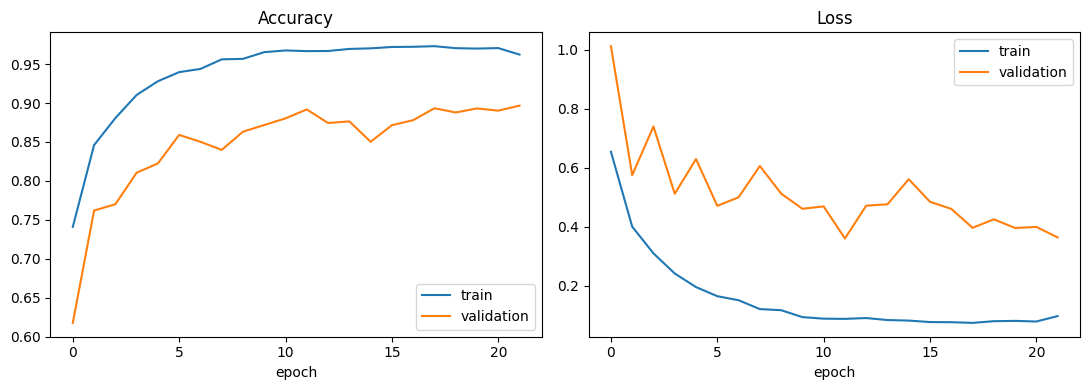

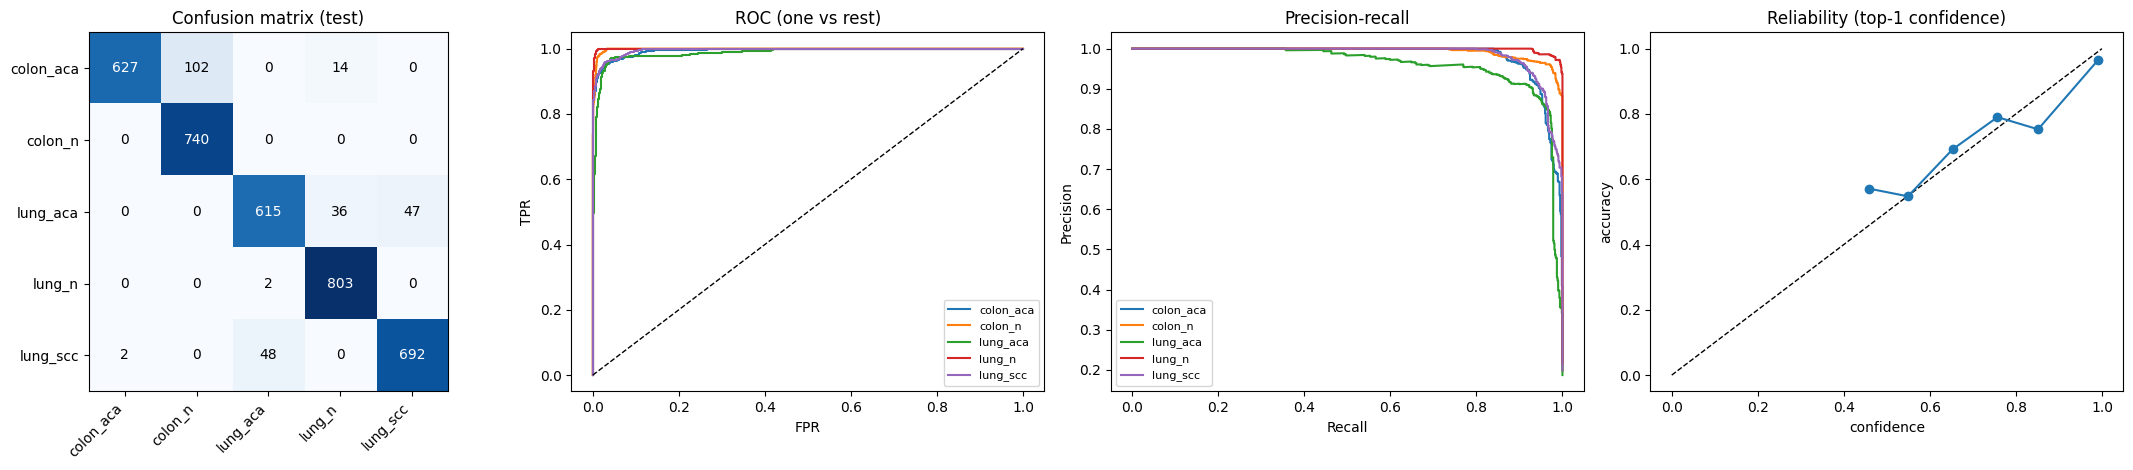

[main | seed 44] split=group | train=17676, val=3595, test=3729
Epoch 1/50
553/553 - 34s - 61ms/step - accuracy: 0.7585 - loss: 0.6174 - val_accuracy: 0.7396 - val_loss: 0.5944 - learning_rate: 1.0000e-04
Epoch 2/50
553/553 - 26s - 48ms/step - accuracy: 0.8470 - loss: 0.3803 - val_accuracy: 0.7805 - val_loss: 0.5446 - learning_rate: 1.0000e-04
Epoch 3/50
553/553 - 26s - 47ms/step - accuracy: 0.8827 - loss: 0.2994 - val_accuracy: 0.7967 - val_loss: 0.6025 - learning_rate: 1.0000e-04
Epoch 4/50
553/553 - 27s - 48ms/step - accuracy: 0.9110 - loss: 0.2346 - val_accuracy: 0.8367 - val_loss: 0.4868 - learning_rate: 1.0000e-04
Epoch 5/50
553/553 - 41s - 74ms/step - accuracy: 0.9236 - loss: 0.2003 - val_accuracy: 0.8729 - val_loss: 0.3583 - learning_rate: 1.0000e-04
Epoch 6/50
553/553 - 26s - 47ms/step - accuracy: 0.9368 - loss: 0.1671 - val_accuracy: 0.8565 - val_loss: 0.4957 - learning_rate: 1.0000e-04
Epoch 7/50
553/553 - 26s - 47ms/step - accuracy: 0.9413 - loss: 0.1550 - val_accuracy: 0.8

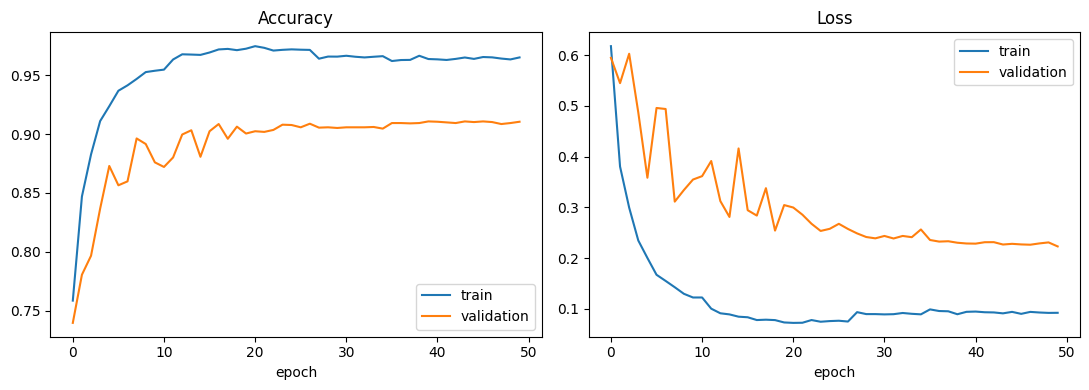

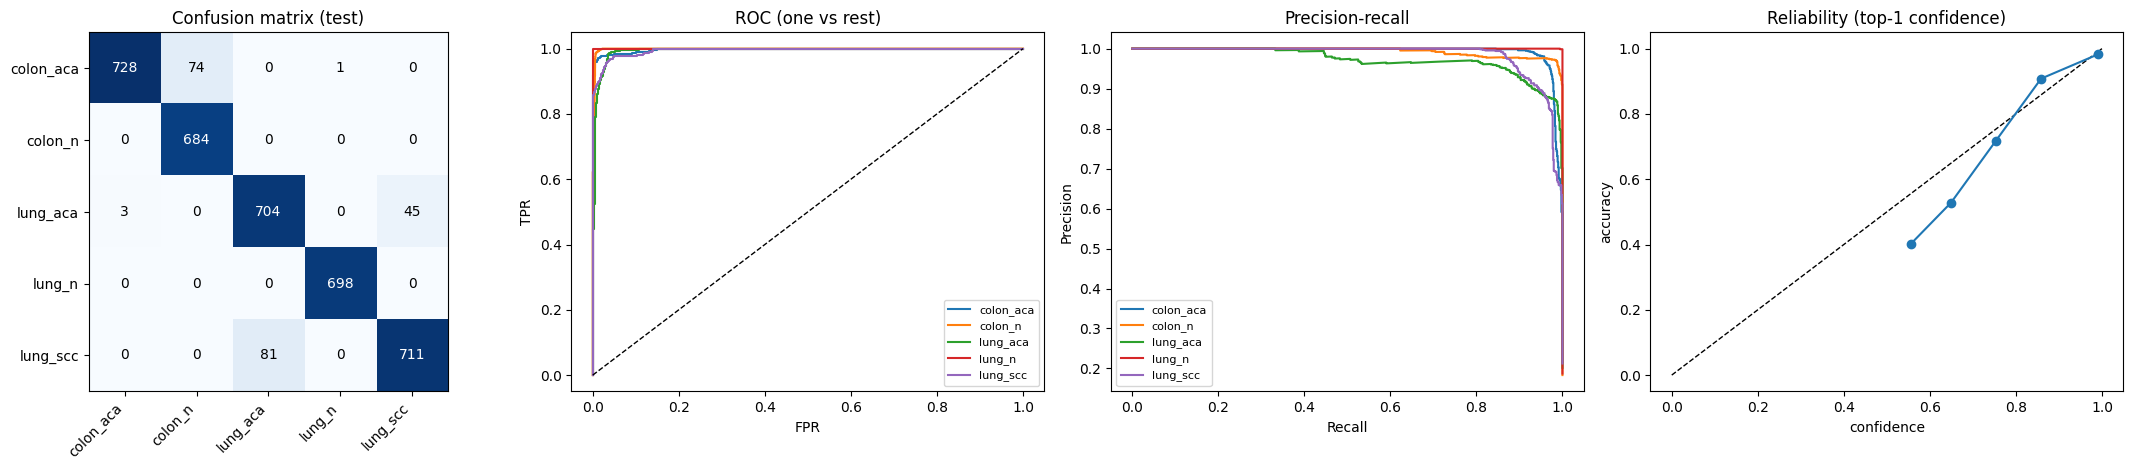

In [11]:
def run_experiment(tag, seed, split_mode='group', model_kw=None, make_plots=True, force=False):
    model_kw = model_kw or {}
    rpath = f'{RUNS}/{tag}_seed{seed}.json'
    if os.path.exists(rpath) and not force:
        print(f'[{tag} | seed {seed}] found saved result, skipping'); return json.load(open(rpath))
    split = get_split(seed, split_mode)
    idx = {s: np.where(split == s)[0] for s in ('train', 'val', 'test')}
    print(f'[{tag} | seed {seed}] split={split_mode} | ' + ', '.join(f'{k}={len(v)}' for k, v in idx.items()))
    keras.backend.clear_session(); apply_precision(); gc.collect(); keras.utils.set_random_seed(seed)
    model = build_lccnet(**model_kw)
    model.compile(keras.optimizers.Adam(CFG['LR']), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    mode = 'min' if 'loss' in CFG['MONITOR'] else 'max'
    wpath = f'{RUNS}/{tag}_seed{seed}.weights.h5'
    cbs = [keras.callbacks.EarlyStopping(CFG['MONITOR'], mode=mode, patience=CFG['PATIENCE'], restore_best_weights=True),
           keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=3, verbose=1),
           keras.callbacks.ModelCheckpoint(wpath, monitor=CFG['MONITOR'], mode=mode, save_best_only=True, save_weights_only=True)]
    t0 = time.time()
    h = model.fit(make_ds(idx['train'], True, seed), validation_data=make_ds(idx['val'], False),
                  epochs=CFG['EPOCHS'], callbacks=cbs, verbose=2)
    train_time = time.time() - t0
    model.load_weights(wpath)                                   # always evaluate the best checkpoint
    hist = {k: [float(x) for x in v] for k, v in h.history.items()}
    best_ep = int(np.argmin(hist[CFG['MONITOR']]) if mode == 'min' else np.argmax(hist[CFG['MONITOR']])) + 1

    res = dict(tag=tag, seed=seed, split_mode=split_mode, model_kw=model_kw, params=int(model.count_params()),
               n={k: int(len(v)) for k, v in idx.items()}, epochs_run=len(hist['loss']), best_epoch=best_ep,
               train_time_s=round(train_time, 1), mixed_precision=keras.mixed_precision.global_policy().name)
    probs = {}
    for s in ('train', 'val', 'test'):
        probs[s] = model.predict(make_ds(idx[s], False), verbose=0)
        res[s] = compute_metrics(y_all[idx[s]], probs[s]) if s != 'train' else dict(accuracy=float(accuracy_score(y_all[idx[s]], probs[s].argmax(1))))
    res['test_ci95'] = group_bootstrap_ci(y_all[idx['test']], probs['test'], df['group'].values[idx['test']], CFG['N_BOOT'])
    np.savez_compressed(f'{RUNS}/{tag}_seed{seed}_testpreds.npz', idx=idx['test'], y=y_all[idx['test']], prob=probs['test'],
                        group=df['group'].values[idx['test']])
    json.dump(dict(res, history=hist), open(rpath, 'w'))
    print(f"  train {res['train']['accuracy']:.4f} | val {res['val']['accuracy']:.4f} | test {res['test']['accuracy']:.4f} "
          f"| macro-F1 {res['test']['macro_f1']:.4f} | MCC {res['test']['mcc']:.4f} | best epoch {best_ep} | {train_time / 60:.1f} min")
    if make_plots:
        plot_curves(hist, f'{PLOTS}/{tag}_seed{seed}_curves.png'); plot_eval(y_all[idx['test']], probs['test'], f'{tag}_seed{seed}')
    del model; gc.collect()
    return res

main_results = [run_experiment('main', s) for s in CFG['SEEDS']]

## 7. Results table
With one seed the intervals come from the group bootstrap on the test set. With several seeds the table also reports the mean and SD across seeds.

In [12]:
def summary_table(results):
    keys = ['accuracy', 'macro_f1', 'mcc', 'kappa', 'balanced_acc', 'auroc_macro', 'auprc_macro', 'ece']
    rows = [{'seed': r['seed'], **{k: r['test'][k] for k in keys}} for r in results]
    t = pd.DataFrame(rows).set_index('seed')
    if len(results) > 1:
        m, sd = t.mean(), t.std()
        t.loc['mean'] = m; t.loc['sd'] = sd
    return t.round(4)

print(summary_table(main_results).to_string())
r0 = main_results[0]
print(f"\nGroup-bootstrap 95% CI (seed {r0['seed']}):")
for k, (lo, hi) in r0['test_ci95'].items():
    print(f"  {k:13s} {r0['test'][k]:.4f}  [{lo:.4f}, {hi:.4f}]")
print(f"\nPer-class test metrics (seed {r0['seed']}):")
print(pd.DataFrame(r0['test']['per_class']).T.round(4).to_string())

      accuracy  macro_f1     mcc   kappa  balanced_acc  auroc_macro  auprc_macro     ece
seed                                                                                    
42      0.8973    0.8964  0.8762  0.8716        0.8980       0.9909       0.9681  0.0670
43      0.9327    0.9310  0.9169  0.9158        0.9310       0.9951       0.9842  0.0318
44      0.9453    0.9464  0.9322  0.9316        0.9481       0.9968       0.9882  0.0186
mean    0.9251    0.9246  0.9084  0.9063        0.9257       0.9943       0.9801  0.0391
sd      0.0249    0.0256  0.0289  0.0311        0.0255       0.0031       0.0106  0.0250

Group-bootstrap 95% CI (seed 42):
  accuracy      0.8973  [0.8427, 0.9429]
  macro_f1      0.8964  [0.8347, 0.9407]
  mcc           0.8762  [0.8143, 0.9289]
  balanced_acc  0.8980  [0.8540, 0.9394]

Per-class test metrics (seed 42):
           sensitivity  specificity   auroc   auprc
colon_aca       0.7685       0.9993  0.9959  0.9856
colon_n         0.9960       0.9376  0.

## 7b. Are the errors concentrated in a few groups?
If a handful of groups hold most of the errors, the confidence interval is wide for a structural reason, and those groups are worth looking at by eye.

In [13]:
def group_error_report(seed):
    tp_ = np.load(f'{RUNS}/main_seed{seed}_testpreds.npz')
    pred_ = tp_['prob'].argmax(1)
    g = pd.DataFrame({'group': tp_['group'], 'true': [CLASSES[i] for i in tp_['y']],
                      'pred': [CLASSES[i] for i in pred_], 'wrong': pred_ != tp_['y']})
    per = g.groupby('group').agg(cls=('true', 'first'), n=('wrong', 'size'), errors=('wrong', 'sum'))
    per['error_rate'] = per['errors'] / per['n']
    per = per.sort_values('errors', ascending=False)
    tot = int(per['errors'].sum())
    shares = {k: float(per['errors'].head(k).sum() / max(tot, 1)) for k in (1, 3, 5, 10)}
    top = per.head(10).copy()
    wrong_g = g[g['wrong']].groupby('group')['pred'].agg(lambda x: x.value_counts().iloc[0] / len(x))
    top['dominant_wrong_label_share'] = wrong_g.reindex(top.index)
    return dict(seed=seed, errors=tot, groups_with_errors=int((per['errors'] > 0).sum()), test_groups=int(len(per)), shares=shares), top

err_summaries = []
for s_ in CFG['SEEDS']:
    summ, top = group_error_report(s_); err_summaries.append(summ)
    print(f"seed {s_}: {summ['errors']} test errors in {summ['groups_with_errors']} of {summ['test_groups']} test groups | " +
          ' | '.join(f'top {k} groups: {v:.0%}' for k, v in summ['shares'].items()))
    if s_ == CFG['SEEDS'][0]:
        print(top.round(3).to_string())

seed 42: 389 test errors in 24 of 138 test groups | top 1 groups: 19% | top 3 groups: 37% | top 5 groups: 50% | top 10 groups: 76%
             cls    n  errors  error_rate  dominant_wrong_label_share
group                                                                
20051   lung_aca   86      74       0.860                         1.0
20032   lung_aca  109      42       0.385                         1.0
3      colon_aca   86      28       0.326                         1.0
20023   lung_aca   26      26       1.000                         1.0
106    colon_aca   24      24       1.000                         1.0
20018   lung_aca  101      22       0.218                         1.0
17     colon_aca   43      22       0.512                         1.0
81     colon_aca   21      21       1.000                         1.0
154    colon_aca   18      18       1.000                         1.0
20142   lung_aca   17      17       1.000                         1.0
seed 43: 251 test errors in 2

## 8. Efficiency: parameters, size, FLOPs, latency
FLOPs are counted analytically from the layer shapes (2 x multiply-accumulates). That includes the attention matrix products, which some profilers skip. Latency is measured on the current device with the current precision policy.

In [14]:
def analytic_macs(model):
    macs = 0
    for l in model.layers:
        n = l.__class__.__name__
        if n == 'Conv2D':
            _, h, w, co = l.output.shape; ci = l.input.shape[-1]; kh, kw = l.kernel_size
            macs += h * w * kh * kw * ci * co
        elif n == 'Dense':
            o = l.output.shape; rows = int(np.prod(o[1:-1])) if len(o) > 2 else 1
            macs += rows * l.input.shape[-1] * o[-1]
        elif n == 'MultiHeadAttention':
            c = l.get_config(); h, k = c['num_heads'], c['key_dim']; L, d = l.output.shape[1], l.output.shape[2]
            macs += 3 * L * d * h * k + 2 * h * L * L * k + L * h * k * d
    return macs

def measure_latency(model, bs, n=100, warm=20):
    x = tf.random.uniform((bs, IMG, IMG, 3), 0, 255)
    f = tf.function(lambda t: model(t, training=False))
    for _ in range(warm): f(x).numpy()
    ts = []
    for _ in range(n):
        t = time.perf_counter(); f(x).numpy(); ts.append((time.perf_counter() - t) * 1000)
    return float(np.mean(ts)), float(np.std(ts)), float(np.percentile(ts, 95))

def load_trained(tag, seed, model_kw=None):
    keras.backend.clear_session(); apply_precision()
    mdl = build_lccnet(**(model_kw or {})); mdl.load_weights(f'{RUNS}/{tag}_seed{seed}.weights.h5'); return mdl

mdl = load_trained('main', CFG['SEEDS'][0])
macs = analytic_macs(mdl)
l1, l1sd, l1p95 = measure_latency(mdl, 1); lb, _, _ = measure_latency(mdl, 32, n=50)
eff = dict(params=mdl.count_params(), size_MB_fp32=round(mdl.count_params() * 4 / 1e6, 2), GMACs=round(macs / 1e9, 4),
           GFLOPs=round(2 * macs / 1e9, 4), latency_bs1_ms=f'{l1:.2f} +/- {l1sd:.2f} (p95 {l1p95:.2f})',
           latency_bs32_ms=round(lb, 2), throughput_img_s=round(32 / lb * 1000, 1),
           device='GPU' if tf.config.list_physical_devices('GPU') else 'CPU', precision=keras.mixed_precision.global_policy().name)
json.dump(eff, open(f'{RUNS}/efficiency.json', 'w'), indent=1)
print(pd.Series(eff).to_string())

params                                459589
size_MB_fp32                            1.84
GMACs                                 0.2659
GFLOPs                                0.5318
latency_bs1_ms      2.21 +/- 0.44 (p95 2.40)
latency_bs32_ms                        11.35
throughput_img_s                      2820.0
device                                   GPU
precision                            float32


## 9. Grad-CAM
Two maps per image. `pool3` is the convolution stage (16x16). `tb2_drop` is the output of the last Transformer block, reshaped back to its 16x16 token grid, so it shows what the attention stage uses. The examples are test images: the first correct case of each class and up to five errors.

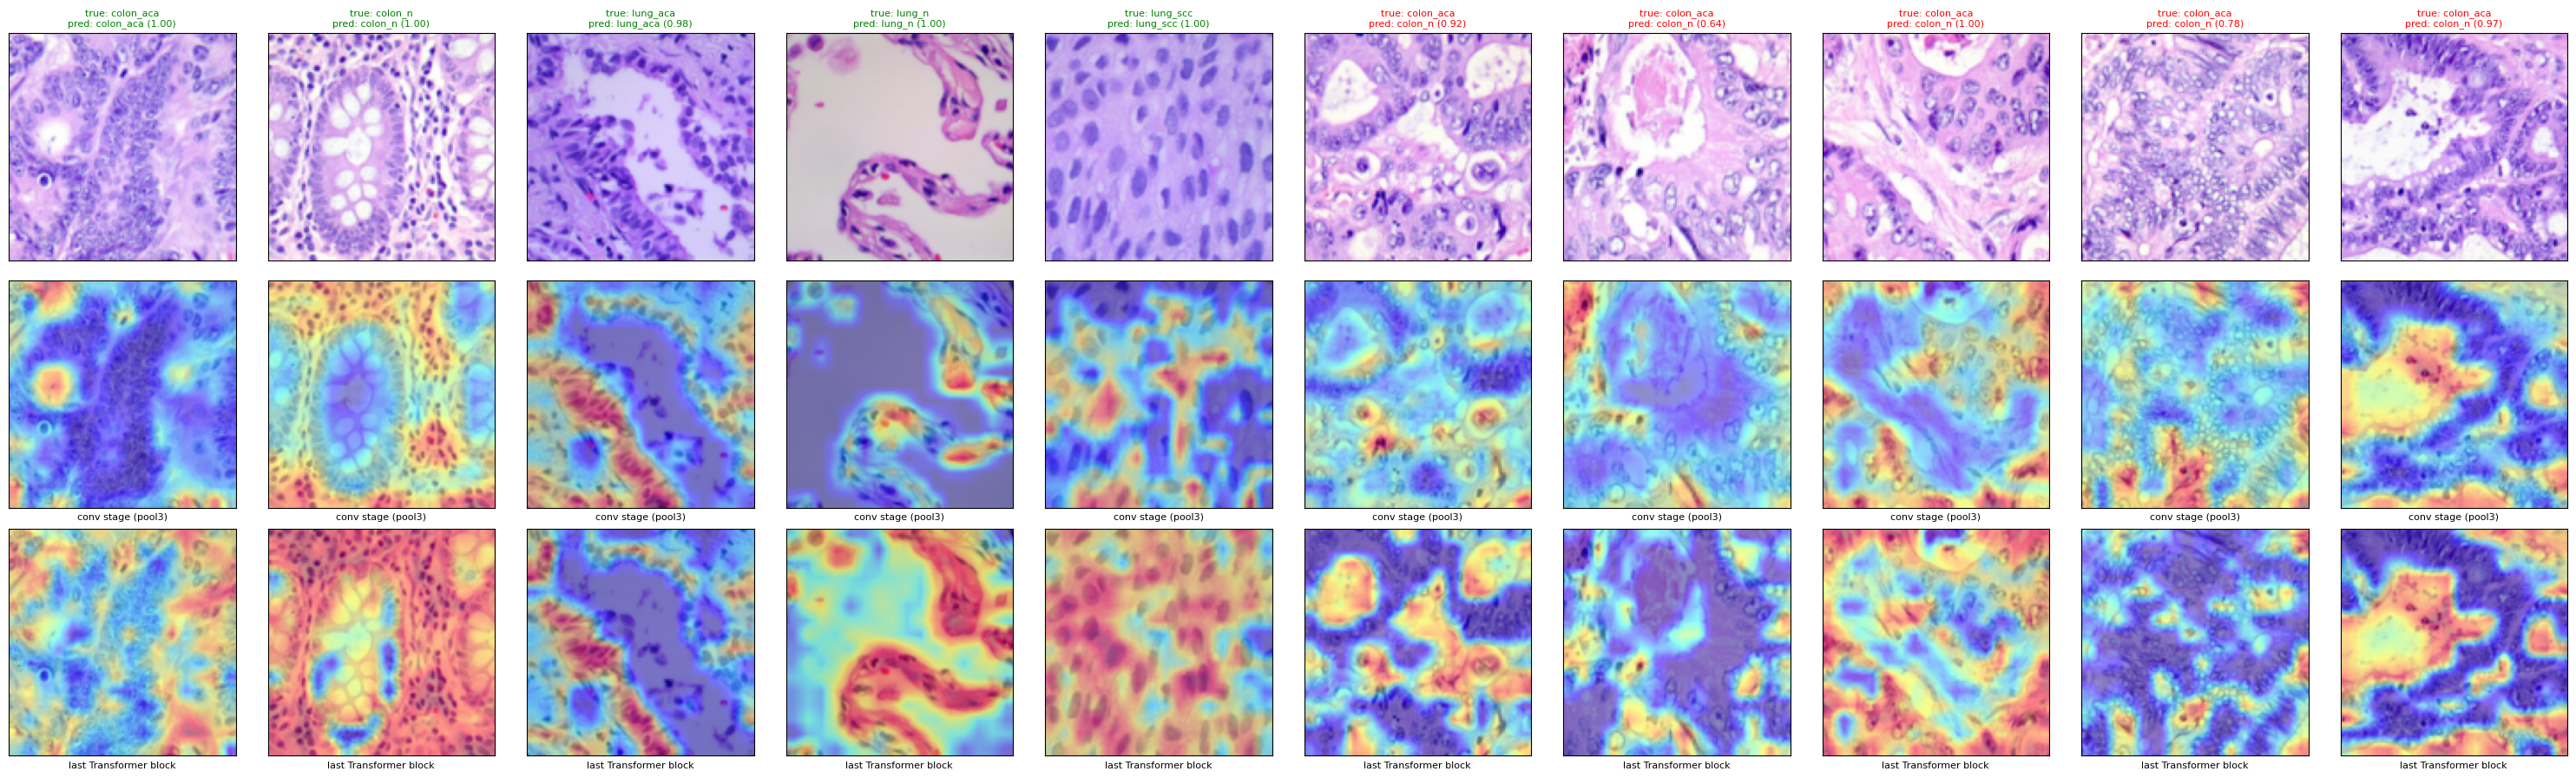

In [15]:
def make_gradcam(model, layer_name):
    gm = keras.Model(model.input, [model.get_layer(layer_name).output, model.output])
    def cam(x, cls=None):
        with tf.GradientTape() as tape:
            feat, pred = gm(x, training=False)
            c = int(tf.argmax(pred[0])) if cls is None else cls
            score = tf.cast(pred[:, c], tf.float32)
        g = tape.gradient(score, feat); feat = tf.cast(feat, tf.float32); g = tf.cast(g, tf.float32)
        if feat.shape.rank == 3:
            s = int(round(feat.shape[1] ** 0.5)); feat = tf.reshape(feat, (-1, s, s, feat.shape[-1])); g = tf.reshape(g, (-1, s, s, g.shape[-1]))
        w = tf.reduce_mean(g, axis=(1, 2))
        h = tf.nn.relu(tf.reduce_sum(feat * w[:, None, None, :], -1))[0]
        return (h / (tf.reduce_max(h) + 1e-8)).numpy(), c, pred.numpy()[0]
    return cam

tp = np.load(f'{RUNS}/main_seed{CFG["SEEDS"][0]}_testpreds.npz')
pred = tp['prob'].argmax(1)
chosen = [int(np.where((tp['y'] == c) & (pred == c))[0][0]) for c in range(len(CLASSES)) if ((tp['y'] == c) & (pred == c)).any()]
chosen += list(np.where(pred != tp['y'])[0][:5])
cams = {n: make_gradcam(mdl, n) for n in ('pool3', 'tb2_drop')}

fig, ax = plt.subplots(3, len(chosen), figsize=(3 * len(chosen), 9), squeeze=False)
for j, i in enumerate(chosen):
    img = X[tp['idx'][i]]; x = img[None].astype(np.float32)
    ax[0, j].imshow(img); ax[0, j].set_title(f"true: {CLASSES[tp['y'][i]]}\npred: {CLASSES[pred[i]]} ({tp['prob'][i].max():.2f})", fontsize=8,
                                              color='green' if pred[i] == tp['y'][i] else 'red')
    for r, name in enumerate(('pool3', 'tb2_drop'), start=1):
        hm, _, _ = cams[name](x)
        hm = tf.image.resize(hm[..., None], (IMG, IMG)).numpy()[..., 0]
        ax[r, j].imshow(img); ax[r, j].imshow(hm, cmap='jet', alpha=0.45)
        ax[r, j].set_xlabel('conv stage (pool3)' if r == 1 else 'last Transformer block', fontsize=8)
    for r in range(3): ax[r, j].set_xticks([]); ax[r, j].set_yticks([])
plt.tight_layout(); plt.savefig(f'{PLOTS}/gradcam_examples.png', dpi=300); plt.show()
del mdl, cams

## 10. Random-split control (optional)
Trains the same model on a naive random split where near-duplicates can sit on both sides. The gap between this run and the `main` run is a direct estimate of how much leakage inflated the earlier numbers. It costs one extra training run.

In [16]:
ctrl = None
if CFG['RUN_RANDOM_SPLIT_CONTROL']:
    ctrl = run_experiment('control_random', CFG['SEEDS'][0], split_mode='random', make_plots=False)
    keys_ = ['accuracy', 'macro_f1', 'mcc', 'balanced_acc', 'auroc_macro', 'ece']
    cmp_ = pd.DataFrame({'random split (control)': {k: ctrl['test'][k] for k in keys_},
                         'group-disjoint (main)': {k: main_results[0]['test'][k] for k in keys_}})
    cmp_['difference'] = cmp_['random split (control)'] - cmp_['group-disjoint (main)']
    print(cmp_.astype(float).round(4).to_string())
    for name_, r_ in (('random split', ctrl), ('group-disjoint', main_results[0])):
        lo, hi = r_['test_ci95']['accuracy']
        print(f"{name_:15s} test accuracy {r_['test']['accuracy']:.4f}  95% CI [{lo:.4f}, {hi:.4f}]  (test n = {r_['n']['test']})")
    print('Same model, same training recipe. Only the split differs, so the difference is the effect of leakage.')
else:
    print('Skipped. Set RUN_RANDOM_SPLIT_CONTROL = True in the config cell to run it.')

[control_random | seed 42] split=random | train=17500, val=3750, test=3750
Epoch 1/50
547/547 - 34s - 62ms/step - accuracy: 0.7766 - loss: 0.5743 - val_accuracy: 0.7304 - val_loss: 0.6012 - learning_rate: 1.0000e-04
Epoch 2/50
547/547 - 26s - 48ms/step - accuracy: 0.8618 - loss: 0.3459 - val_accuracy: 0.7936 - val_loss: 0.5196 - learning_rate: 1.0000e-04
Epoch 3/50
547/547 - 40s - 74ms/step - accuracy: 0.8891 - loss: 0.2856 - val_accuracy: 0.8027 - val_loss: 0.5803 - learning_rate: 1.0000e-04
Epoch 4/50
547/547 - 26s - 48ms/step - accuracy: 0.9131 - loss: 0.2304 - val_accuracy: 0.8443 - val_loss: 0.4410 - learning_rate: 1.0000e-04
Epoch 5/50
547/547 - 27s - 49ms/step - accuracy: 0.9337 - loss: 0.1768 - val_accuracy: 0.8899 - val_loss: 0.3109 - learning_rate: 1.0000e-04
Epoch 6/50
547/547 - 26s - 47ms/step - accuracy: 0.9409 - loss: 0.1592 - val_accuracy: 0.8616 - val_loss: 0.4389 - learning_rate: 1.0000e-04
Epoch 7/50
547/547 - 27s - 49ms/step - accuracy: 0.9459 - loss: 0.1464 - val_ac

## 11. Ablation under the full protocol (optional)
Every variant uses the same split, seed, 50-epoch budget and early stopping as the main model. The earlier ablation used 10 epochs, which is why its full model scored 95.96%.

`cnn_only_param_matched` adds two 3x3 convolutions at 16x16 so the CNN-only model has about the same parameter count as LCC-Net. Without it, the CNN-only result mixes the effect of attention with the effect of capacity. `shallow_cnn_2stage` uses filters 32 and 128, which reproduces the 0.503M parameters in the paper.

In [20]:
ABLATION = {
    'full':                   {},
    'no_pos_emb':             dict(use_pos=False),
    'cnn_only':               dict(n_blocks=0),
    'cnn_only_param_matched': dict(n_blocks=0, extra_convs=2),
    'single_block':           dict(n_blocks=1),
    'shallow_cnn_2stage':     dict(n_stages=2),
    'no_augmentation':        dict(augment=False),
    'head_128':               dict(head_dim=128),
}
if CFG['RUN_ABLATION']:
    seed = CFG['SEEDS'][0]
    abl = {}
    for name, kw in ABLATION.items():
        abl[name] = main_results[0] if name == 'full' else run_experiment(f'abl_{name}', seed, model_kw=kw, make_plots=False)
    base = abl['full']['test']['accuracy']
    tab = pd.DataFrame([{'variant': n, 'params_M': r['params'] / 1e6, 'val_acc': r['val']['accuracy'], 'test_acc': r['test']['accuracy'],
                         'delta_pp': 100 * (r['test']['accuracy'] - base), 'macro_f1': r['test']['macro_f1'], 'mcc': r['test']['mcc'],
                         'epochs': r['epochs_run'], 'train_min': r['train_time_s'] / 60} for n, r in abl.items()]).round(4)
    tab.to_csv(f'{OUT}/ablation_full_protocol.csv', index=False)
    print(tab.to_string(index=False))
else:
    print('Skipped. Set RUN_ABLATION = True in the config cell to run it (8 training runs, resumable).')

[abl_no_pos_emb | seed 42] split=group | train=17514, val=3699, test=3787
Epoch 1/50
548/548 - 33s - 60ms/step - accuracy: 0.7792 - loss: 0.5683 - val_accuracy: 0.7616 - val_loss: 0.5609 - learning_rate: 1.0000e-04
Epoch 2/50
548/548 - 26s - 47ms/step - accuracy: 0.8623 - loss: 0.3433 - val_accuracy: 0.7521 - val_loss: 0.7475 - learning_rate: 1.0000e-04
Epoch 3/50
548/548 - 26s - 47ms/step - accuracy: 0.9043 - loss: 0.2500 - val_accuracy: 0.8875 - val_loss: 0.3217 - learning_rate: 1.0000e-04
Epoch 4/50
548/548 - 26s - 48ms/step - accuracy: 0.9379 - loss: 0.1685 - val_accuracy: 0.9008 - val_loss: 0.3142 - learning_rate: 1.0000e-04
Epoch 5/50
548/548 - 26s - 48ms/step - accuracy: 0.9504 - loss: 0.1438 - val_accuracy: 0.9154 - val_loss: 0.2304 - learning_rate: 1.0000e-04
Epoch 6/50
548/548 - 27s - 50ms/step - accuracy: 0.9568 - loss: 0.1223 - val_accuracy: 0.9359 - val_loss: 0.1863 - learning_rate: 1.0000e-04
Epoch 7/50
548/548 - 26s - 47ms/step - accuracy: 0.9617 - loss: 0.1078 - val_acc

## Files saved to Drive
- `runs/split_group_seed*.csv`: the exact train, validation and test partitions. Use these for ResNet, VGG, DNN and HDE-HistNet so every model sees the same data.
- `runs/main_seed*.json`: all metrics, confidence intervals and training history.
- `runs/main_seed*_testpreds.npz`: test probabilities, for McNemar tests and bootstrap comparisons against the baselines.
- `runs/efficiency.json`, `plots/`, `groups.csv`, `embeddings_mnv2_128.npy`, `images_128.npy`.

## 12. Everything the paper needs, in one file
Writes `paper_numbers.md` to Drive and prints it. Send me this text (or the file) and I will put the numbers into the paper.

In [18]:
def fmt_ci(r, k):
    lo, hi = r['test_ci95'][k]; return f"{r['test'][k]:.4f} [{lo:.4f}, {hi:.4f}]"

L = ['# LCC-Net numbers for the paper', '',
     f"Config: seeds {CFG['SEEDS']}, patience {CFG['PATIENCE']}, max epochs {CFG['EPOCHS']}, batch {CFG['BATCH']}, lr {CFG['LR']}, "
     f"precision {main_results[0]['mixed_precision']}, groups per class {CFG['GROUPS_PER_CLASS']}, split {CFG['SPLIT']}", '',
     '## Group-disjoint split, per seed (test)']
for r in main_results:
    L.append(f"- seed {r['seed']}: acc {fmt_ci(r,'accuracy')}, macro-F1 {fmt_ci(r,'macro_f1')}, MCC {fmt_ci(r,'mcc')}, "
             f"balanced acc {fmt_ci(r,'balanced_acc')}, AUROC {r['test']['auroc_macro']:.4f}, AUPRC {r['test']['auprc_macro']:.4f}, "
             f"ECE {r['test']['ece']:.4f}; train {r['train']['accuracy']:.4f}, val {r['val']['accuracy']:.4f}; "
             f"epochs run {r['epochs_run']}, best epoch {r['best_epoch']}, {r['train_time_s']/60:.1f} min; n = {r['n']}")
L += ['', '## Mean and SD across seeds', '```', summary_table(main_results).to_string(), '```', '',
      '## Per-class test metrics (first seed)', '```', pd.DataFrame(main_results[0]['test']['per_class']).T.round(4).to_string(), '```', '',
      'Confusion matrix (first seed, rows = true, columns = predicted; order ' + ', '.join(CLASSES) + '):', '```',
      str(np.array(main_results[0]['test']['confusion_matrix'])), '```', '',
      '## Leakage diagnostic (cosine similarity of each test image to its nearest training image)', '```',
      pd.DataFrame(diag).round(4).to_string(index=False), '```', '']
sz_ = df.groupby('group').size()
L += [f"Groups: {len(sz_)}, images per group: min {sz_.min()}, median {int(sz_.median())}, max {sz_.max()}", '']
L += ['## Errors by group']
for e in err_summaries:
    L.append(f"- seed {e['seed']}: {e['errors']} errors in {e['groups_with_errors']} of {e['test_groups']} test groups; " +
             ', '.join(f"top {k}: {v:.0%}" for k, v in e['shares'].items()))
if ctrl is not None:
    L += ['', '## Random-split control (first seed) versus group-disjoint (first seed)',
          f"- random split: acc {fmt_ci(ctrl,'accuracy')}, macro-F1 {fmt_ci(ctrl,'macro_f1')}, MCC {fmt_ci(ctrl,'mcc')}, ECE {ctrl['test']['ece']:.4f}; train {ctrl['train']['accuracy']:.4f}, val {ctrl['val']['accuracy']:.4f}; n = {ctrl['n']}",
          f"- group-disjoint: acc {fmt_ci(main_results[0],'accuracy')}, macro-F1 {fmt_ci(main_results[0],'macro_f1')}",
          f"- accuracy difference: {100*(ctrl['test']['accuracy']-main_results[0]['test']['accuracy']):.2f} percentage points"]
L += ['', '## Efficiency', '```', json.dumps(eff, indent=1), '```']
abl_csv = f'{OUT}/ablation_full_protocol.csv'
if os.path.exists(abl_csv):
    L += ['', '## Ablation (full protocol, first seed)', '```', pd.read_csv(abl_csv).to_string(index=False), '```']
txt = '\n'.join(L)
open(f'{OUT}/paper_numbers.md', 'w').write(txt)
print(txt)

# LCC-Net numbers for the paper

Config: seeds [42, 43, 44], patience 10, max epochs 50, batch 32, lr 0.0001, precision float32, groups per class 200, split (0.7, 0.15, 0.15)

## Group-disjoint split, per seed (test)
- seed 42: acc 0.8973 [0.8427, 0.9429], macro-F1 0.8964 [0.8347, 0.9407], MCC 0.8762 [0.8143, 0.9289], balanced acc 0.8980 [0.8540, 0.9394], AUROC 0.9909, AUPRC 0.9681, ECE 0.0670; train 0.9382, val 0.9167; epochs run 14, best epoch 9, 7.0 min; n = {'train': 17514, 'val': 3699, 'test': 3787}
- seed 43: acc 0.9327 [0.8957, 0.9640], macro-F1 0.9310 [0.8917, 0.9632], MCC 0.9169 [0.8718, 0.9546], balanced acc 0.9310 [0.8955, 0.9635], AUROC 0.9951, AUPRC 0.9842, ECE 0.0318; train 0.9277, val 0.8917; epochs run 22, best epoch 12, 10.1 min; n = {'train': 17421, 'val': 3851, 'test': 3728}
- seed 44: acc 0.9453 [0.9101, 0.9738], macro-F1 0.9464 [0.9128, 0.9715], MCC 0.9322 [0.8859, 0.9665], balanced acc 0.9481 [0.9200, 0.9730], AUROC 0.9968, AUPRC 0.9882, ECE 0.0186; train 0.9456, 